# Atividade Experimental VII — Processamento Digital de Sinais
**UFPB — PPGEE | 2026.2**  
**Aluno(a):** ANDRÉ PONTES 


Conversões de BMP para GIF, PNG e JPEG (90 e 15), PSNR, taxa de compressão,
análise espacial, FFT 2D e 50 regravações por formato.

Mantenha o BMP na pasta do notebook e indique seu nome em `ARQUIVO_BMP`.
Execute as células em ordem. No Colab, envie o BMP pelo painel de arquivos.
Se necessário: `%pip install numpy pillow matplotlib`.
Os resultados são gravados em `resultados/`; reexecutar substitui os arquivos de mesmo nome.


## 1. Configuração

Altere `ARQUIVO_BMP` para selecionar outro BMP. Os resultados ficam em `resultados/`.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

ARQUIVO_BMP = Path('sample_1280×853.bmp')
SAIDA = Path('resultados')
GERACOES = 50
FORMATOS = {
    'GIF': ('.gif', {}),
    'PNG': ('.png', {}),
    'JPEG90': ('.jpg', {'quality': 90, 'subsampling': 2}),
    'JPEG15': ('.jpg', {'quality': 15, 'subsampling': 2}),
}
SAIDA.mkdir(exist_ok=True)

## 2. Entrada BMP e referência 512 × 512

A entrada deve ser BMP. Imagens de outro tamanho recebem um recorte central proporcional para 512 × 512. O BMP preparado é a referência das métricas.

Entrada: sample_1280×853.bmp — (1280, 853)
Referência: (512, 512) — 786,486 bytes


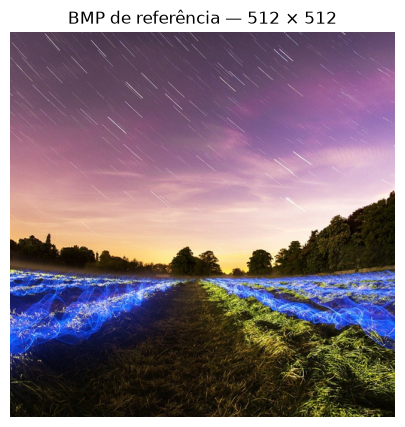

In [2]:
with Image.open(ARQUIVO_BMP) as arquivo:
    if arquivo.format != 'BMP':
        raise ValueError('Selecione um arquivo no formato BMP.')
    tamanho_entrada = arquivo.size
    original = arquivo.convert('RGB')

if original.size != (512, 512):
    original = ImageOps.fit(original, (512, 512), method=Image.Resampling.LANCZOS)

caminho_bmp = SAIDA / 'original_512.bmp'
original.save(caminho_bmp)
pixels_originais = np.asarray(original, dtype=float)
bytes_bmp = caminho_bmp.stat().st_size

print(f'Entrada: {ARQUIVO_BMP.name} — {tamanho_entrada}')
print(f'Referência: {original.size} — {bytes_bmp:,} bytes')
plt.figure(figsize=(5, 5))
plt.imshow(original)
plt.title('BMP de referência — 512 × 512')
plt.axis('off')
plt.show()

## 3. Funções

PSNR RGB = $10\log_{10}(255^2/MSE)$. Erro zero implica PSNR infinito. As medidas usam imagens reabertas após a gravação.

In [3]:
def abrir_rgb(caminho):
    """Abre uma imagem gravada e devolve seus pixels RGB."""
    with Image.open(caminho) as imagem:
        return imagem.convert('RGB')


def salvar_imagem(imagem, caminho, formato):
    """Grava usando as configurações fixas do formato."""
    opcoes = FORMATOS[formato][1]
    if formato == 'GIF':
        imagem = imagem.quantize(colors=256, method=Image.Quantize.MEDIANCUT,
                                  dither=Image.Dither.NONE)
    imagem.save(caminho, **opcoes)


def calcular_psnr(imagem):
    """Calcula o PSNR RGB em relação ao BMP de referência."""
    diferenca = pixels_originais - np.asarray(imagem, dtype=float)
    mse = np.mean(diferenca ** 2)
    return np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def exportar_csv(caminho, linhas):
    """Exporta uma tabela de resultados para CSV."""
    with caminho.open('w', newline='', encoding='utf-8-sig') as arquivo:
        tabela = csv.DictWriter(arquivo, fieldnames=linhas[0].keys())
        tabela.writeheader()
        tabela.writerows(linhas)

## 4. Conversões e comparação

Taxa de compressão = bytes do BMP de referência ÷ bytes do arquivo convertido. Quanto maior a taxa, menor o arquivo.

In [4]:
imagens = {'BMP': original}
metricas = [{'formato': 'BMP', 'bytes': bytes_bmp,
             'taxa_compressao': 1.0, 'psnr_db': np.inf}]

for formato, (extensao, opcoes) in FORMATOS.items():
    caminho = SAIDA / f'{formato}{extensao}'
    salvar_imagem(original, caminho, formato)
    imagem = abrir_rgb(caminho)
    imagens[formato] = imagem
    tamanho = caminho.stat().st_size
    metricas.append({
        'formato': formato,
        'bytes': tamanho,
        'taxa_compressao': bytes_bmp / tamanho,
        'psnr_db': calcular_psnr(imagem),
    })

print(f'{"Formato":<10} {"Bytes":>10} {"Taxa":>10} {"PSNR (dB)":>12}')
for linha in metricas:
    print(f'{linha["formato"]:<10} {linha["bytes"]:>10} '
          f'{linha["taxa_compressao"]:>10.2f} {linha["psnr_db"]:>12.2f}')

exportar_csv(SAIDA / 'metricas_conversao.csv', metricas)
assert np.array_equal(pixels_originais, np.asarray(imagens['PNG']))

Formato         Bytes       Taxa    PSNR (dB)


BMP            786486       1.00          inf
GIF            170176       4.62        32.90
PNG            494505       1.59          inf
JPEG90          87680       8.97        35.21
JPEG15          13376      58.80        25.82


## 5. Análise espacial

Os mesmos recortes são ampliados em todos os formatos. Ao trocar a imagem, ajuste `REGIOES` para selecionar uma área suave e outra com textura.

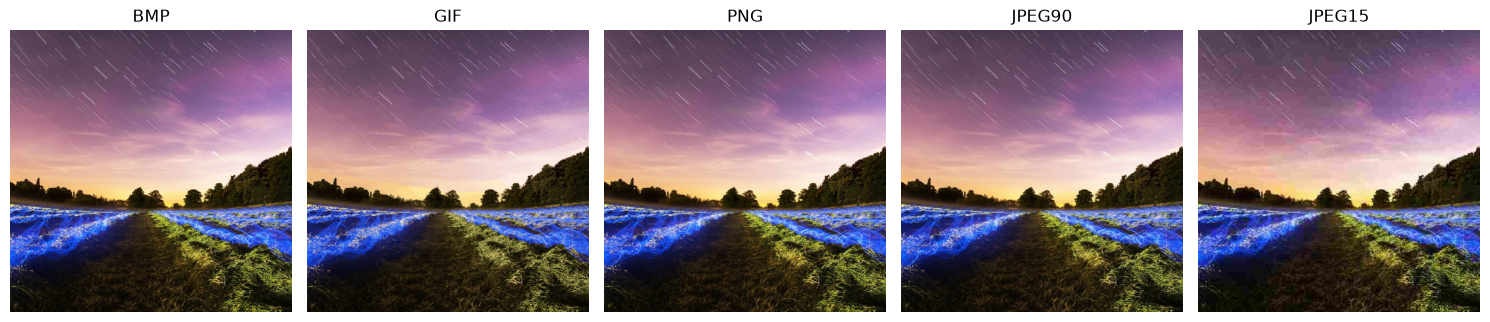

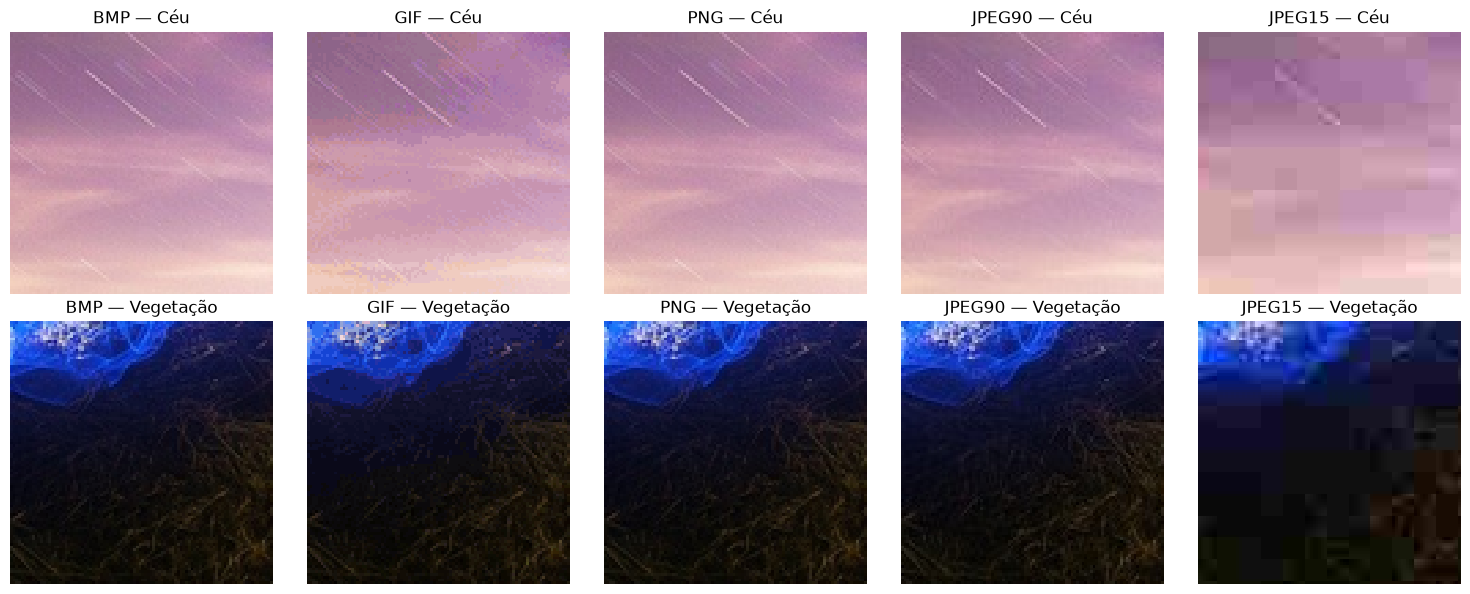

In [5]:
REGIOES = {
    'Céu': (220, 150, 316, 246),
    'Vegetação': (65, 385, 161, 481),
}

fig, eixos = plt.subplots(1, 5, figsize=(15, 4))
for eixo, (formato, imagem) in zip(eixos, imagens.items()):
    eixo.imshow(imagem)
    eixo.set_title(formato)
    eixo.axis('off')
fig.tight_layout()
fig.savefig(SAIDA / 'comparacao.png')
plt.show()

fig, eixos = plt.subplots(2, 5, figsize=(15, 6))
for linha, (regiao, caixa) in enumerate(REGIOES.items()):
    for coluna, (formato, imagem) in enumerate(imagens.items()):
        eixo = eixos[linha, coluna]
        eixo.imshow(imagem.crop(caixa), interpolation='nearest')
        eixo.set_title(f'{formato} — {regiao}')
        eixo.axis('off')
fig.tight_layout()
fig.savefig(SAIDA / 'zoom.png')
plt.show()

## 6. FFT 2D

FFT da intensidade $Y=0{,}299R+0{,}587G+0{,}114B$, centrada e exibida como $\ln(1+|F|)$. Todos os painéis usam a mesma escala.

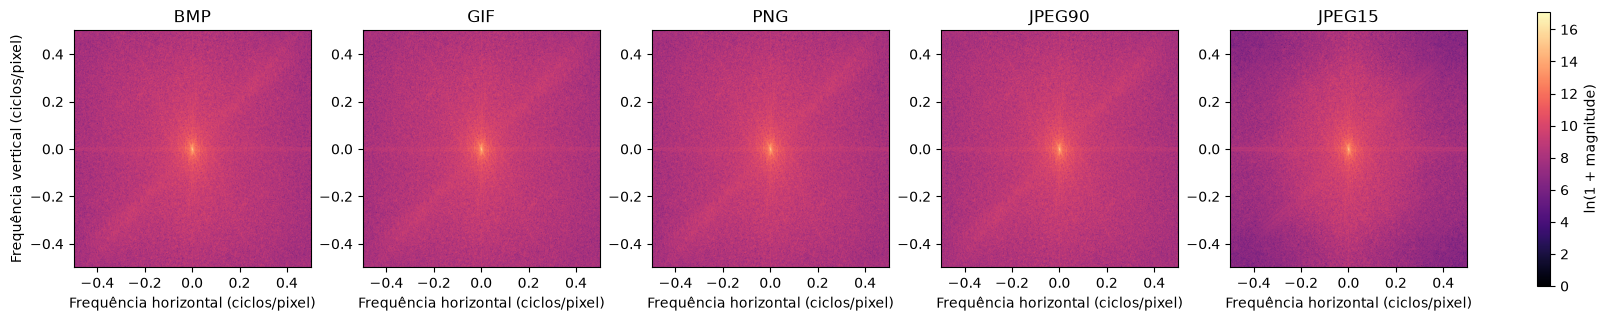

In [6]:
def calcular_espectro(imagem):
    """Retorna a log-magnitude centrada da FFT 2D da intensidade."""
    rgb = np.asarray(imagem, dtype=float)
    intensidade = rgb @ [0.299, 0.587, 0.114]
    transformada = np.fft.fftshift(np.fft.fft2(intensidade))
    return np.log1p(np.abs(transformada))


espectros = {nome: calcular_espectro(imagem) for nome, imagem in imagens.items()}
limite = max(espectro.max() for espectro in espectros.values())

fig, eixos = plt.subplots(1, 5, figsize=(16, 4), layout='constrained')
for eixo, (formato, espectro) in zip(eixos, espectros.items()):
    painel = eixo.imshow(espectro, cmap='magma', vmin=0, vmax=limite,
                         extent=(-0.5, 0.5, -0.5, 0.5))
    eixo.set_title(formato)
    eixo.set_xlabel('Frequência horizontal (ciclos/pixel)')
eixos[0].set_ylabel('Frequência vertical (ciclos/pixel)')
fig.colorbar(painel, ax=list(eixos), label='ln(1 + magnitude)', shrink=0.7)
fig.savefig(SAIDA / 'fft.png')
plt.show()

## 7. Cascata — 50 regravações por formato

Usa-se a opção de apenas salvar novamente, permitida pelo enunciado. Cada geração recebe o arquivo da geração anterior, sem rotação.

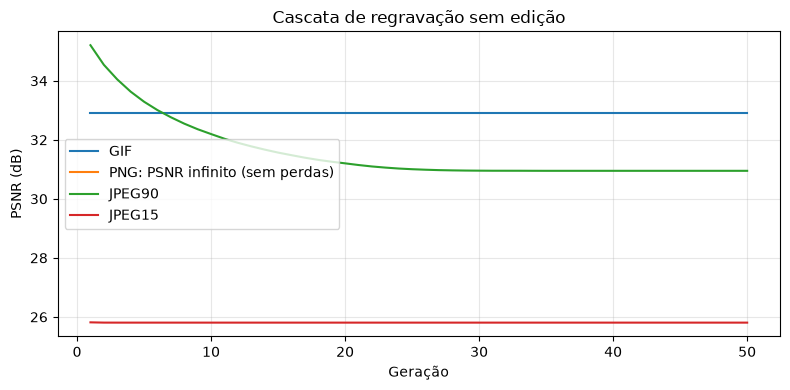

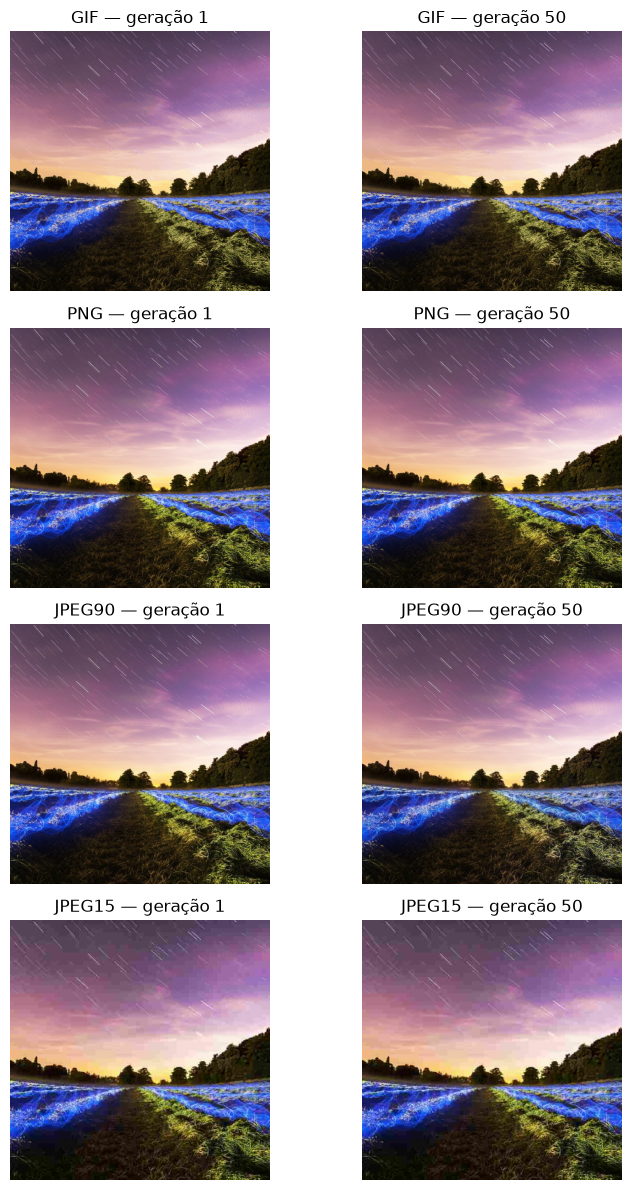

Formato       PSNR geração 1    PSNR geração 50
GIF                    32.90              32.90
PNG                      inf                inf
JPEG90                 35.21              30.95
JPEG15                 25.82              25.81


In [7]:
historico = []
amostras = {}

for formato, (extensao, opcoes) in FORMATOS.items():
    pasta = SAIDA / 'cascata' / formato
    pasta.mkdir(parents=True, exist_ok=True)
    imagem = original.copy()

    for geracao in range(1, GERACOES + 1):
        caminho = pasta / f'geracao_{geracao:02d}{extensao}'
        salvar_imagem(imagem, caminho, formato)
        imagem = abrir_rgb(caminho)
        historico.append({
            'formato': formato,
            'geracao': geracao,
            'bytes': caminho.stat().st_size,
            'psnr_db': calcular_psnr(imagem),
        })
        if geracao in (1, GERACOES):
            amostras[formato, geracao] = imagem.copy()

exportar_csv(SAIDA / 'metricas_cascata.csv', historico)

plt.figure(figsize=(8, 4))
for formato in FORMATOS:
    valores = [linha['psnr_db'] for linha in historico if linha['formato'] == formato]
    if np.isinf(valores).all():
        plt.plot([], [], label=f'{formato}: PSNR infinito (sem perdas)')
    else:
        plt.plot(range(1, GERACOES + 1), valores, label=formato)
plt.xlabel('Geração')
plt.ylabel('PSNR (dB)')
plt.title('Cascata de regravação sem edição')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAIDA / 'curva_cascata.png')
plt.show()

fig, eixos = plt.subplots(4, 2, figsize=(8, 12))
for linha, formato in enumerate(FORMATOS):
    for coluna, geracao in enumerate((1, GERACOES)):
        eixo = eixos[linha, coluna]
        eixo.imshow(amostras[formato, geracao])
        eixo.set_title(f'{formato} — geração {geracao}')
        eixo.axis('off')
fig.tight_layout()
fig.savefig(SAIDA / 'comparacao_cascata.png')
plt.show()

print(f'{"Formato":<10} {"PSNR geração 1":>17} {"PSNR geração 50":>18}')
for formato in FORMATOS:
    valores = [linha['psnr_db'] for linha in historico if linha['formato'] == formato]
    print(f'{formato:<10} {valores[0]:>17.2f} {valores[-1]:>18.2f}')

## 8. Discussão e conclusão


**BMP e PNG:** os pixels e espectros coincidem; PNG reduz o tamanho sem perdas.

**GIF:** a paleta limitada modifica tons suaves do céu e detalhes de cor da vegetação.
No BMP usado nesta execução, o zoom evidencia faixas de tonalidade. A quantização
também muda a distribuição do espectro, sem um corte simples de frequências.

**JPEG 90:** mantém melhor os traços finos do céu e a textura da vegetação que JPEG 15,
mas altera pixels e componentes espectrais. A subamostragem de cor também causa perdas.

**JPEG 15:** o céu apresenta blocos visíveis e os detalhes da vegetação ficam suavizados.
A FFT mostra alterações maiores, incluindo estruturas regulares. Compressão JPEG
não equivale a um filtro passa-baixas ideal: blocos também podem criar frequências.

**Cascata:** compare os valores da geração 1 e 50. GIF pode estabilizar após a primeira
quantização, e JPEG pode apresentar pouca perda adicional sem edição. PNG preserva
os pixels em todas as gerações. A ausência de rotação permite atribuir as diferenças
à codificação. O ensaio não simula novas perdas decorrentes de editar ou redimensionar
a imagem entre os compartilhamentos.

As observações espaciais se referem ao BMP fornecido. Ao trocar a entrada, ajuste os
recortes e reveja os comentários. Os números abaixo são recalculados a cada execução.


In [8]:
menor = min(metricas[1:], key=lambda linha: linha['bytes'])
print(f'Menor arquivo: {menor["formato"]}, taxa {menor["taxa_compressao"]:.2f}:1.')
print('PNG: reconstrução exata do BMP de referência.')

for formato in FORMATOS:
    primeira = next(linha for linha in historico
                    if linha['formato'] == formato and linha['geracao'] == 1)
    ultima = next(linha for linha in historico
                  if linha['formato'] == formato and linha['geracao'] == GERACOES)
    if np.isinf(ultima['psnr_db']):
        print(f'{formato}: sem perda de pixels nas {GERACOES} gerações.')
    elif np.isclose(primeira['psnr_db'], ultima['psnr_db']):
        print(f'{formato}: PSNR estável em {ultima["psnr_db"]:.2f} dB.')
    else:
        print(f'{formato}: PSNR passou de {primeira["psnr_db"]:.2f} '
              f'para {ultima["psnr_db"]:.2f} dB.')

Menor arquivo: JPEG15, taxa 58.80:1.
PNG: reconstrução exata do BMP de referência.
GIF: PSNR estável em 32.90 dB.
PNG: sem perda de pixels nas 50 gerações.
JPEG90: PSNR passou de 35.21 para 30.95 dB.
JPEG15: PSNR passou de 25.82 para 25.81 dB.
